In [7]:
#Subiectul 1, a

import numpy as np
from hmmlearn import hmm


states = ["C1", "C2", "C3", "C4"]
observations = ["red", "green", "blue"]


model = hmm.CategoricalHMM(n_components=4, random_state=42)


model.startprob_ = np.array([1/4, 1/4, 1/4, 1/4])


model.transmat_ = np.array([
    [0.2, 0.4, 0.0, 0.4],
    [0.4, 0.2, 0.4, 0.0], 
    [0.0, 0.4, 0.2, 0.4],
    [0.4, 0.0, 0.4, 0.2]   
])

model.emissionprob_ = np.array([
    [0.7, 0.2, 0.1],  #1
    [0.2, 0.6, 0.2],  #2
    [0.1, 0.3, 0.6],  #3
    [0.5, 0.2, 0.3]   #4
])

 
obs_seq = np.array([[0], [1], [2], [2], [0]])

log_prob_viterbi, hidden_states = model.decode(obs_seq, algorithm="viterbi")
decoded_names = [states[s] for s in hidden_states]

print(f"Secvența optimă (indecși):    {hidden_states}")
print(f"Secvența optimă (stări):      {decoded_names}")
print(f"Probabilitatea drumului:      {np.exp(log_prob_viterbi):.6f}")

Secvența optimă (indecși):    [0 1 2 3 0]
Secvența optimă (stări):      ['C1', 'C2', 'C3', 'C4', 'C1']
Probabilitatea drumului:      0.000339


In [8]:
# 1, b


import numpy as np
from hmmlearn import hmm


states = ["C1", "C2", "C3", "C4"]
observations = ["red", "green", "blue"]


model = hmm.CategoricalHMM(n_components=4, random_state=42)


model.startprob_ = np.array([1/4, 1/4, 1/4, 1/4])


model.transmat_ = np.array([
    [0.0, 0.5, 0.0, 0.5],
    [0.5, 0.0, 0.5, 0.0], 
    [0.0, 0.5, 0.0, 0.5],
    [0.5, 0.0, 0.5, 0.0]   
])


model.emissionprob_ = np.array([
    [0.7, 0.2, 0.1],  #1
    [0.2, 0.6, 0.2],  #2
    [0.1, 0.3, 0.6],  #3
    [0.5, 0.2, 0.3]   #4
])


obs_seq = np.array([[0], [1], [2], [2], [0]])

log_prob_viterbi, hidden_states = model.decode(obs_seq, algorithm="viterbi")
decoded_names = [states[s] for s in hidden_states]

print(f"Secvența optimă (indecși):    {hidden_states}")
print(f"Secvența optimă (stări):      {decoded_names}")
print(f"Probabilitatea drumului:      {np.exp(log_prob_viterbi):.6f}")

Secvența optimă (indecși):    [0 1 2 3 0]
Secvența optimă (stări):      ['C1', 'C2', 'C3', 'C4', 'C1']
Probabilitatea drumului:      0.000827


1.b) Este prezisa aceeasi secventa de camere, doar ca la punctul b secventa este prezisa cu o probabilitate mai mare

Distributia a posteriori: Beta((7, 23))
Media a posteriori: 0.2333


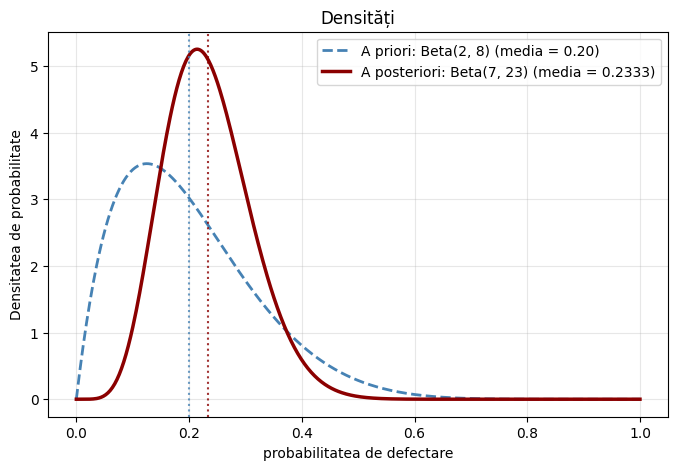

In [9]:
#Subiect 3, a

import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt


alpha_prior = 2 
beta_prior =  8
n = 20
y = 5


alpha_post = alpha_prior + y
beta_post = beta_prior + n - y

print(f"Distributia a posteriori: Beta({alpha_post,beta_post})")


p = np.linspace(0, 1, 500)

prior_pdf = stats.beta.pdf(p, alpha_prior, beta_prior)
post_pdf = stats.beta.pdf(p, alpha_post, beta_post)

mean_prior = alpha_prior / (alpha_prior + beta_prior)
mean_post = alpha_post / (alpha_post + beta_post)

print(f"Media a posteriori: {mean_post:.4f}")


plt.figure(figsize=(8, 5))
plt.plot(p, prior_pdf, '--', color='steelblue', lw=2, label=f'A priori: Beta(2, 8) (media = {mean_prior:.2f})')
plt.plot(p, post_pdf, '-', color='darkred', lw=2.5, label=f'A posteriori: Beta(7, 23) (media = {mean_post:.4f})')


plt.axvline(mean_prior, color='steelblue', linestyle=':', alpha=0.8)
plt.axvline(mean_post, color='darkred', linestyle=':', alpha=0.8)

plt.title('Densități')
plt.xlabel('probabilitatea de defectare')
plt.ylabel('Densitatea de probabilitate')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [10]:
#3, b
import scipy.stats as stats


alpha_prior2 = 7
beta_prior2 = 23

n2 = 15
y2 = 3

alpha_post2 = alpha_prior2 + y2
beta_post2 = beta_prior2 + n2 - y2


media_post2 = stats.beta.mean(alpha_post2, beta_post2)

print(f"Noua distribuție a posteriori: Beta({alpha_post2}, {beta_post2})")
print(f"Noua medie a posteriori: {media_post2:.4f}")

Noua distribuție a posteriori: Beta(10, 35)
Noua medie a posteriori: 0.2222
